# CNN de deteccion de danos v3

Cambios respecto de `cnn_damage_detection_training2.ipynb`:
1. **Superficies sanas de cerca** (`undamaged_superficies`, armado con `cnn_damage_detection_superficies_ETL.ipynb`)
   se suman a las undamaged. Asi el modelo deja de asociar "pared de cerca" con "dano".
2. **Label smoothing** (0,05) en la loss, para que no termine dando siempre 0 % o 100 %.
3. **Calibracion** con *temperature scaling* sobre validacion y **umbral** elegido en validacion en vez de 0,5 fijo.
   Se guardan en `models/modelo_detection3_calibracion.json` y el backend los usa.
4. La evaluacion muestra el acierto por grupo, incluidas las superficies sanas, y el error de calibracion (ECE).

Es el mismo modelo (CNN de 4 bloques desde cero) y el mismo esquema de split 70/15/15 que la v2.
No pisa `modelo_detection2.keras`: guarda en `modelo_detection3.keras`.

In [4]:
# Celda 1: imports, seeds y configuracion
# Igual que la v2, con estas diferencias:
#   - las undamaged son las de deteccion + las superficies sanas
#   - PROP_CLASIF sube a 0.45: como hay mas undamaged, el cupo de damaged
#     crece y las damaged de deteccion no alcanzan solas. Ademas, mas fotos
#     de dano de cerca (las de clasificacion) contra superficies sanas de
#     cerca obligan al modelo a mirar el dano y no el encuadre.
#   - LABEL_SMOOTHING: en vez de etiquetas 0/1 usa 0.025/0.975
# Etiquetas igual que antes: damaged = 0, undamaged = 1, asi la salida
# sigmoid sigue siendo la probabilidad de "undamaged" y el backend no cambia.

import os
import gc
import json
import hashlib
import random
import subprocess

import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

LOCAL_DATA_DIR = "../data"  # los datos quedan en notebooks/, fuera de parte3
BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed/damage_detection"

DATASET_CSV = "../data_clasificacion/dataset_final.csv"
PROP_CLASIF = 0.45
LABEL_SMOOTHING = 0.05

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

CLASS_NAMES = ["damaged", "undamaged"]
MODEL_PATH = "../../models/modelo_detection3.keras"
CALIB_PATH = "../../models/modelo_detection3_calibracion.json"
CONTINUAR = False  # True solo para retomar un entrenamiento que se corto (ver celda 11)

In [5]:
# Celda 2: verificar que las imagenes de deteccion esten en disco
# Las baja descargar_datos_deteccion3.ipynb (correrlo antes, una sola
# vez). Aca solo se chequea que esten las tres carpetas.
# Depende de: LOCAL_DATA_DIR (celda 1)

for carpeta in ["damaged", "undamaged", "undamaged_superficies"]:
    if not os.path.isdir(f"{LOCAL_DATA_DIR}/{carpeta}") or not os.listdir(f"{LOCAL_DATA_DIR}/{carpeta}"):
        raise FileNotFoundError(f"Falta {LOCAL_DATA_DIR}/{carpeta}: correr antes descargar_datos_deteccion3.ipynb")

for carpeta in ["damaged", "undamaged"]:
    print(f"{carpeta}: {len(os.listdir(f'{LOCAL_DATA_DIR}/{carpeta}'))}")
for fuente in sorted(os.listdir(f"{LOCAL_DATA_DIR}/undamaged_superficies")):
    print(f"undamaged_superficies/{fuente}: {len(os.listdir(f'{LOCAL_DATA_DIR}/undamaged_superficies/{fuente}'))}")

damaged: 11194
undamaged: 12981
undamaged_superficies/ozgenel_negative: 2500
undamaged_superficies/sdnet_uw: 2500


In [6]:
# Celda 3: verificar el dataset de clasificacion
# Igual que la v2: necesita dataset_final.csv (de cnn_damage_classification_build_dataset.ipynb).
# Depende de: DATASET_CSV (celda 1)

if not os.path.exists(DATASET_CSV):
    raise FileNotFoundError(f"No existe {DATASET_CSV}: correr antes descargar_datos_deteccion3.ipynb")

clasif_df = pd.read_csv(DATASET_CSV)
# las rutas del csv son relativas a notebooks/; este notebook esta en notebooks/parte3
clasif_df["image_path"] = "../" + clasif_df["image_path"]
no_estan = [r for r in clasif_df["image_path"] if not os.path.exists(r)]
if no_estan:
    raise FileNotFoundError(f"{len(no_estan)} de {len(clasif_df)} imagenes no estan en disco (ej: {no_estan[0]})")

print(f"Dataset de clasificacion OK: {len(clasif_df)} imagenes, todas en disco")

Dataset de clasificacion OK: 39497 imagenes, todas en disco


In [7]:
# Celda 4: imagenes de deteccion y superficies, split train/val/test (70/15/15)
# Las de deteccion se separan igual que en la v2 (mismo random_state), asi
# el test de deteccion es el mismo. Las superficies se separan aparte,
# estratificadas por fuente, y entran como "undamaged" con origen
# "superficies" y grupo = fuente (sdnet_uw, ozgenel_negative, propias).
# Calcula el md5 de cada archivo para no repetir fotos entre fuentes.
# Depende de: LOCAL_DATA_DIR, CLASS_NAMES, SEED (celda 1)

FORMATOS_OK = (".jpg", ".jpeg", ".png", ".gif", ".bmp")

def md5_archivo(ruta):
    with open(ruta, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

filas = []
for clase in CLASS_NAMES:
    carpeta = f"{LOCAL_DATA_DIR}/{clase}"
    for archivo in sorted(os.listdir(carpeta)):
        if archivo.lower().endswith(FORMATOS_OK):
            filas.append({"image_path": f"{carpeta}/{archivo}", "clase": clase,
                          "origen": "deteccion", "grupo": f"{clase} (deteccion)"})
det_df = pd.DataFrame(filas)

det_train, det_resto = train_test_split(det_df, test_size=0.30, stratify=det_df["clase"], random_state=SEED)
det_val, det_test = train_test_split(det_resto, test_size=0.50, stratify=det_resto["clase"], random_state=SEED)
det_df["split"] = "train"
det_df.loc[det_val.index, "split"] = "val"
det_df.loc[det_test.index, "split"] = "test"

filas = []
base_sup = f"{LOCAL_DATA_DIR}/undamaged_superficies"
for fuente in sorted(os.listdir(base_sup)):
    for archivo in sorted(os.listdir(f"{base_sup}/{fuente}")):
        if archivo.lower().endswith(FORMATOS_OK):
            filas.append({"image_path": f"{base_sup}/{fuente}/{archivo}", "clase": "undamaged",
                          "origen": "superficies", "grupo": fuente})
sup_df = pd.DataFrame(filas)
s_train, s_resto = train_test_split(sup_df, test_size=0.30, stratify=sup_df["grupo"], random_state=SEED)
s_val, s_test = train_test_split(s_resto, test_size=0.50, stratify=s_resto["grupo"], random_state=SEED)
sup_df["split"] = "train"
sup_df.loc[s_val.index, "split"] = "val"
sup_df.loc[s_test.index, "split"] = "test"

det_df = pd.concat([det_df, sup_df], ignore_index=True)
det_df["hash"] = det_df["image_path"].map(md5_archivo)
antes = len(det_df)
det_df = det_df.drop_duplicates("hash").reset_index(drop=True)
print(f"Duplicados exactos descartados: {antes - len(det_df)}\n")

print(pd.crosstab([det_df["clase"], det_df["origen"]], det_df["split"])[["train", "val", "test"]])

Duplicados exactos descartados: 62

split                  train   val  test
clase     origen                        
damaged   deteccion     7834  1679  1679
undamaged deteccion     9043  1935  1942
          superficies   3500   750   750


In [8]:
# Celda 5: cuantas imagenes damaged se toman de cada fuente
# Igual que la v2: en cada split, cupo de damaged = cantidad de undamaged
# (ahora incluye las superficies). PROP_CLASIF de ese cupo sale de
# clasificacion y el resto de deteccion.
# Depende de: det_df (celda 4), PROP_CLASIF (celda 1)

SPLITS = ["train", "val", "test"]

cupos = pd.DataFrame(index=SPLITS)
cupos["undamaged"] = det_df[det_df["clase"] == "undamaged"]["split"].value_counts().reindex(SPLITS)
cupos["damaged_clasif"] = (cupos["undamaged"] * PROP_CLASIF).round().astype(int)
cupos["damaged_deteccion"] = cupos["undamaged"] - cupos["damaged_clasif"]
cupos["deteccion_disponibles"] = det_df[det_df["clase"] == "damaged"]["split"].value_counts().reindex(SPLITS)

faltan = cupos[cupos["damaged_deteccion"] > cupos["deteccion_disponibles"]]
if not faltan.empty:
    raise ValueError(f"No alcanzan las damaged de deteccion en {list(faltan.index)}: subir PROP_CLASIF")

print(cupos)

       undamaged  damaged_clasif  damaged_deteccion  deteccion_disponibles
train      12543            5644               6899                   7834
val         2685            1208               1477                   1679
test        2692            1211               1481                   1679


In [9]:
# Celda 6: imagenes de clasificacion que se agregan como damaged
# Igual que la v2: rearma el split del clasificador (mismo csv y
# random_state=42) para que el test de un modelo nunca este en el train del otro.
# Depende de: clasif_df (celda 3), det_df (celda 4), cupos (celda 5), SEED

c_train, c_resto = train_test_split(clasif_df, test_size=0.30, stratify=clasif_df["label"], random_state=42)
c_val, c_test = train_test_split(c_resto, test_size=0.50, stratify=c_resto["label"], random_state=42)

hashes_deteccion = set(det_df["hash"])
partes = []
for split, parte in zip(SPLITS, [c_train, c_val, c_test]):
    n = cupos.loc[split, "damaged_clasif"]
    frac = min(1.0, n * 1.2 / len(parte))
    candidatas = parte.groupby("label", group_keys=False).sample(frac=frac, random_state=SEED).copy()
    candidatas["hash"] = candidatas["image_path"].map(md5_archivo)
    repetidas = candidatas["hash"].isin(hashes_deteccion)
    candidatas = candidatas[~repetidas].drop_duplicates("hash")
    if len(candidatas) < n:
        raise ValueError(f"{split}: quedaron {len(candidatas)} imagenes de clasificacion y hacen falta {n}")
    muestra = candidatas.sample(n=n, random_state=SEED)
    print(f"{split}: {repetidas.sum()} candidatas descartadas por estar ya en deteccion, se toman {n}")
    partes.append(pd.DataFrame({
        "image_path": muestra["image_path"].values,
        "clase": "damaged",
        "origen": "clasificacion",
        "grupo": muestra["label"].values,
        "split": split,
    }))
extra_df = pd.concat(partes, ignore_index=True)
print(f"\nSe agregan {len(extra_df)} imagenes de clasificacion como damaged")

train: 884 candidatas descartadas por estar ya en deteccion, se toman 5644
val: 192 candidatas descartadas por estar ya en deteccion, se toman 1208
test: 189 candidatas descartadas por estar ya en deteccion, se toman 1211

Se agregan 8063 imagenes de clasificacion como damaged


In [10]:
# Celda 7: dataset combinado y balanceado
# Todas las undamaged (deteccion + superficies) y, en cada split, la
# cantidad de damaged de deteccion que indica el cupo. Label: damaged = 0, undamaged = 1.
# Depende de: det_df (celda 4), cupos (celda 5), extra_df (celda 6)

det_usadas = [det_df[det_df["clase"] == "undamaged"]]
for split in SPLITS:
    disponibles = det_df[(det_df["clase"] == "damaged") & (det_df["split"] == split)]
    det_usadas.append(disponibles.sample(n=cupos.loc[split, "damaged_deteccion"], random_state=SEED))

todo_df = pd.concat(det_usadas + [extra_df], ignore_index=True).drop(columns="hash")
todo_df["label"] = todo_df["clase"].map({c: i for i, c in enumerate(CLASS_NAMES)})

train_df = todo_df[todo_df["split"] == "train"].reset_index(drop=True)
val_df = todo_df[todo_df["split"] == "val"].reset_index(drop=True)
test_df = todo_df[todo_df["split"] == "test"].reset_index(drop=True)

print(pd.crosstab([todo_df["clase"], todo_df["origen"]], todo_df["split"], margins=True)[SPLITS + ["All"]])

por_clase = pd.crosstab(todo_df["clase"], todo_df["split"])
assert (por_clase.loc["damaged"] == por_clase.loc["undamaged"]).all(), "damaged y undamaged no quedaron iguales"
print("\nOK: misma cantidad de damaged y undamaged en cada split")

split                    train   val  test    All
clase     origen                                 
damaged   clasificacion   5644  1208  1211   8063
          deteccion       6899  1477  1481   9857
undamaged deteccion       9043  1935  1942  12920
          superficies     3500   750   750   5000
All                      25086  5370  5384  35840

OK: misma cantidad de damaged y undamaged en cada split


In [11]:
# Celda 8: pipeline de imagenes con tf.data
# Igual que la v2. Las etiquetas van suavizadas solo en train
# (label smoothing): 0 -> LABEL_SMOOTHING/2 y 1 -> 1 - LABEL_SMOOTHING/2.
# En val y test quedan 0/1 para medir bien.
# Depende de: train_df, val_df, test_df (celda 7), IMG_SIZE, BATCH_SIZE, SEED

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_dataset(dataframe, training):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("float32").reshape(-1, 1)
    if training:
        labels = labels * (1 - LABEL_SMOOTHING) + LABEL_SMOOTHING / 2
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(dataframe), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)
print(f"train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

train: 25086 | val: 5370 | test: 5384


E0000 00:00:1792937099.639691  456154 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [12]:
# Celda 9: data augmentation
# Igual que la v2 mas brillo y traslacion: las capturas del robot cambian
# de iluminacion y de encuadre. Solo actua durante el entrenamiento.

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.15, value_range=(0, 1)),
    layers.RandomTranslation(0.1, 0.1),
])

In [13]:
# Celda 10: arquitectura (crear el modelo desde cero)
# La misma CNN de la v2. Siempre se crea; si CONTINUAR = True, la celda 11
# la reemplaza por el ultimo modelo guardado.
# Depende de: data_augmentation (celda 9)

def build_cnn(input_shape=(224, 224, 3)):
    inputs = tf.keras.Input(shape=input_shape)
    x = layers.Rescaling(1./255)(inputs)
    x = data_augmentation(x)
    for filtros in [32, 64, 128, 256]:
        x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return models.Model(inputs, outputs)

model = build_cnn()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [14]:
# Celda 11: retomar un entrenamiento cortado (solo si CONTINUAR = True)
# Normalmente no hace nada. Si el kernel se corto a mitad del
# entrenamiento, poner CONTINUAR = True en la celda 1 y volver a correr
# todo: aca se carga el ultimo modelo guardado y la celda 13 sigue desde ahi.

if CONTINUAR:
    model = tf.keras.models.load_model(MODEL_PATH)
    print(f"Se retoma el entrenamiento desde {MODEL_PATH}")
else:
    print("Entrenamiento desde cero (CONTINUAR = False)")

Entrenamiento desde cero (CONTINUAR = False)


In [15]:
# Celda 12: callbacks
# Iguales a la v2: checkpoint con el menor val_loss y limpieza de memoria.

class MemoryCleanup(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", mode="min", save_best_only=True),
    MemoryCleanup()
]

In [16]:
# Celda 13: entrenamiento
# Se corre UNA sola vez. Entrena hasta 40 epocas y EarlyStopping lo corta
# solo cuando val_loss deja de mejorar durante 8 epocas seguidas, volviendo
# a los mejores pesos. El checkpoint guarda el mejor modelo en cada mejora.
# Solo si el kernel se llega a cortar: poner CONTINUAR = True en la celda 1
# y correr todo de nuevo; sigue desde el ultimo modelo guardado.

EPOCAS_MAX = 40
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCAS_MAX, callbacks=callbacks)

Epoch 1/40


/home/johndoe/Escritorio/dev/pili/humanoid-damage-cnn/.venv/lib64/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1792937103.300305  458607 cpu_allocator_impl.cc:82] Allocation of 23970816 exceeds 10% of free system memory.
W0000 00:00:1792937103.316355  458608 cpu_allocator_impl.cc:82] Allocation of 36499968 exceeds 10% of free system memory.
W0000 00:00:1792937103.330278  458603 cpu_allocator_impl.cc:82] Allocation of 36578304 exceeds 10% of free system memory.
W0000 00:00:1792937103.342657  458606 cpu_allocator_impl.cc:82] Allocation of 23970816 exceeds 10% of free system memory.
W0000 00:00:1792937103.343046  458609 cpu_allocator_impl.cc:82] Allocation of 36499968 exceeds 10% of free system memory.


1568/1568 ━━━━━━━━━━━━━━━━━━━━ 0s 890ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.5264

Invalid SOS parameters for sequential JPEG


1568/1568 ━━━━━━━━━━━━━━━━━━━━ 1450s 922ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.5264 - val_accuracy: 0.6886 - val_auc: 0.7048 - val_loss: 1.0512 - learning_rate: 0.0010
Epoch 2/40
1568/1568 ━━━━━━━━━━━━━━━━━━━━ 0s 908ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.4176

Invalid SOS parameters for sequential JPEG


... (15 outputs left out)

Invalid SOS parameters for sequential JPEG


1568/1568 ━━━━━━━━━━━━━━━━━━━━ 1303s 831ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2494 - val_accuracy: 0.8603 - val_auc: 0.9618 - val_loss: 0.3394 - learning_rate: 5.0000e-04
Epoch 11/40
1568/1568 ━━━━━━━━━━━━━━━━━━━━ 0s 808ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2465

Invalid SOS parameters for sequential JPEG


1568/1568 ━━━━━━━━━━━━━━━━━━━━ 1312s 837ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 0.2465 - val_accuracy: 0.8503 - val_auc: 0.9594 - val_loss: 0.3592 - learning_rate: 5.0000e-04


In [17]:
# Celda 14: calibracion y umbral (sobre VALIDACION)
# 1. Temperature scaling: pasa la salida a logit, la divide por una
#    temperatura T y vuelve a sigmoid. T > 1 "afloja" las probabilidades
#    (menos 0 % y 100 %), T < 1 las "aprieta". Se elige la T que minimiza
#    la log-loss en validacion. No cambia el orden de las predicciones.
# 2. Umbral: en vez de 0.5 fijo, se elige el umbral de P(dano) que da el
#    mejor F1 para la clase damaged en validacion, ya con las
#    probabilidades calibradas.
# Se guarda todo en CALIB_PATH; el backend lo lee.
# Depende de: MODEL_PATH, val_ds, val_df

model = tf.keras.models.load_model(MODEL_PATH)

def a_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def log_loss(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

val_p_undamaged = model.predict(val_ds, verbose=0).ravel()
val_y_damaged = (val_df["label"].values == 0).astype(int)
val_logit_damaged = -a_logit(val_p_undamaged)

temperaturas = np.arange(0.5, 6.01, 0.05)
perdidas = [log_loss(val_y_damaged, sigmoid(val_logit_damaged / t)) for t in temperaturas]
T = float(temperaturas[int(np.argmin(perdidas))])

val_p_damaged = sigmoid(val_logit_damaged / T)
umbrales = np.arange(0.20, 0.81, 0.01)
f1s = [f1_score(val_y_damaged, (val_p_damaged >= u).astype(int)) for u in umbrales]
UMBRAL = float(umbrales[int(np.argmax(f1s))])

with open(CALIB_PATH, "w") as f:
    json.dump({"temperatura": round(T, 3), "umbral_dano": round(UMBRAL, 3),
               "salida_modelo": "probabilidad de undamaged"}, f, indent=2)

print(f"Temperatura: {T:.2f} | umbral de dano: {UMBRAL:.2f} | guardado en {CALIB_PATH}")

Invalid SOS parameters for sequential JPEG


Temperatura: 1.05 | umbral de dano: 0.22 | guardado en ../../models/modelo_detection3_calibracion.json


Invalid SOS parameters for sequential JPEG


              precision    recall  f1-score   support

     damaged       0.90      0.93      0.91      2692
   undamaged       0.92      0.89      0.91      2692

    accuracy                           0.91      5384
   macro avg       0.91      0.91      0.91      5384
weighted avg       0.91      0.91      0.91      5384

ROC-AUC: 0.9674
ECE sin calibrar: 0.011 | calibrado: 0.008



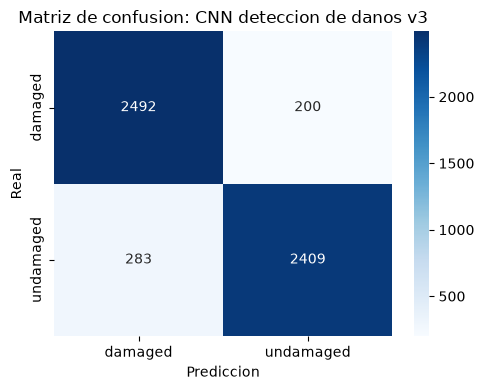

% de aciertos por grupo:
                                           imagenes  acierto
origen        grupo                                         
clasificacion Biological growth                  48     85.4
              Concrete spalling                  12    100.0
              Corrosion                         213     91.5
              Delamination                       96     97.9
              Material loss/erosion              48    100.0
              Moisture/water damage             128     94.5
              Salt weathering                    89     96.6
              Structural crack                  133     91.7
              Surface flaking/exfoliation       235     95.7
              Vandalism                          37     86.5
              Vegetation                        172     99.4
deteccion     damaged (deteccion)              1481     90.8
              undamaged (deteccion)            1942     86.3
superficies   ozgenel_negative                  375     97.9

In [18]:
# Celda 15: evaluacion en test
# Usa las probabilidades calibradas y el umbral de la celda 14.
# Muestra:
#   - reporte por clase, matriz de confusion y ROC-AUC
#   - ECE (error de calibracion) antes y despues de calibrar: cuanto se
#     aleja el % que dice el modelo del % de aciertos real (mas bajo, mejor)
#   - % de aciertos por grupo: para superficies sanas es la proporcion que
#     el modelo reconoce como SIN dano (antes era casi 0 %)
# Depende de: model, test_ds, test_df, T, UMBRAL

def ece(y, p, bins=10):
    bordes = np.linspace(0, 1, bins + 1)
    conf = np.where(p >= 0.5, p, 1 - p)
    pred = (p >= 0.5).astype(int)
    total = 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (conf > a) & (conf <= b)
        if m.any():
            total += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return total

test_p_undamaged = model.predict(test_ds, verbose=0).ravel()
y_damaged = (test_df["label"].values == 0).astype(int)
p_damaged_crudo = 1 - test_p_undamaged
p_damaged = sigmoid(-a_logit(test_p_undamaged) / T)
pred_damaged = (p_damaged >= UMBRAL).astype(int)

y_true = 1 - y_damaged
y_pred = 1 - pred_damaged
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
print(f"ROC-AUC: {roc_auc_score(y_damaged, p_damaged):.4f}")
print(f"ECE sin calibrar: {ece(y_damaged, p_damaged_crudo):.3f} | calibrado: {ece(y_damaged, p_damaged):.3f}\n")

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("Matriz de confusion: CNN deteccion de danos v3")
plt.xlabel("Prediccion")
plt.ylabel("Real")
plt.tight_layout()
plt.show()

res_df = test_df.assign(pred=np.array(CLASS_NAMES)[y_pred], prob_damaged=p_damaged)
res_df["acierto"] = res_df["pred"] == res_df["clase"]
por_grupo = res_df.groupby(["origen", "grupo"]).agg(imagenes=("acierto", "size"), acierto=("acierto", "mean"))
por_grupo["acierto"] = (por_grupo["acierto"] * 100).round(1)
print("% de aciertos por grupo:")
print(por_grupo.to_string())

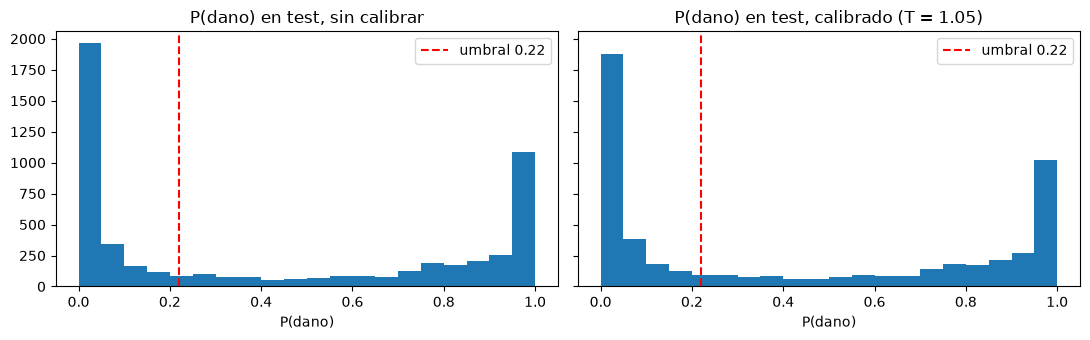

In [19]:
# Celda 16: histograma de confianza
# Compara cuantas predicciones caen en cada rango de P(dano) antes y
# despues de calibrar. Antes casi todo estaba pegado a 0 % o 100 %.

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, p, titulo in zip(axes, [p_damaged_crudo, p_damaged], ["sin calibrar", f"calibrado (T = {T:.2f})"]):
    ax.hist(p, bins=20, range=(0, 1))
    ax.axvline(UMBRAL, color="red", linestyle="--", label=f"umbral {UMBRAL:.2f}")
    ax.set_title(f"P(dano) en test, {titulo}")
    ax.set_xlabel("P(dano)")
    ax.legend()
plt.tight_layout()
plt.show()

In [20]:
# Celda 17: prueba con paredes lisas sinteticas y con la carpeta "prueba"
# Genera paredes lisas (blanca, beige, gris) que el modelo v2 marcaba con
# 100 % de dano, y predice tambien las imagenes de FOLDER_PATH.

FOLDER_PATH = "../prueba"
rng = np.random.default_rng(0)

def pared(base, ruido, grad):
    y = np.linspace(0, 1, 224)[:, None, None]
    img = np.ones((224, 224, 3)) * np.array(base) * (1 - grad * y)
    return np.clip(img + rng.normal(0, ruido, img.shape), 0, 255).astype("float32")

casos = {"pared blanca": pared((242, 242, 238), 2, 0.05), "pared blanca con sombra": pared((240, 240, 236), 3, 0.35),
         "pared beige": pared((222, 205, 180), 5, 0.10), "hormigon gris": pared((150, 150, 148), 12, 0.10)}
for archivo in sorted(f for f in os.listdir(FOLDER_PATH) if f.lower().endswith((".jpg", ".jpeg", ".png"))):
    img, _ = load_image(os.path.join(FOLDER_PATH, archivo), 0)
    casos[archivo] = img.numpy()

for nombre, img in casos.items():
    p_und = float(model.predict(img[None], verbose=0)[0][0])
    p_dan = float(sigmoid(-a_logit(np.array([p_und])) / T)[0])
    print(f"{nombre:30s} P(dano) calibrada: {p_dan:6.1%} -> {'CON dano' if p_dan >= UMBRAL else 'sin dano'}")

pared blanca                   P(dano) calibrada:   5.4% -> sin dano
pared blanca con sombra        P(dano) calibrada:   2.9% -> sin dano
pared beige                    P(dano) calibrada:   2.7% -> sin dano
hormigon gris                  P(dano) calibrada:  98.3% -> CON dano
000012.jpg                     P(dano) calibrada:  99.1% -> CON dano
00007.jpg                      P(dano) calibrada:  92.3% -> CON dano
00009.jpg                      P(dano) calibrada:  99.3% -> CON dano
00011.jpg                      P(dano) calibrada:  89.9% -> CON dano
frame_02400.png                P(dano) calibrada:  28.8% -> CON dano
